**SAPIANS** · SCC5819 · MÓDULO 09 — DECOMPOSIÇÃO FUNCIONAL · MOLNAR, CAP. 22

# Decomposição por dentro — componentes, pesos e ortogonalidade

Depois de H resumir um resíduo, o walkthrough escolheu uma superfície de PD
e pesos produto para construir seus componentes. Aqui conferimos as restrições
que os identificam, além da soma que reconstrói a superfície.

[README do módulo](../README.md) · [outline da aula](../lecture/outline.md) · [Colab](https://colab.research.google.com/github/wbendinelli/interpretable-ml-lectures/blob/main/modules/09-functional-decomposition/notebooks/decomposition_internals.ipynb)

---

**Objetivos.** Confrontar os componentes com a função sintética conhecida;
recalcular médias ponderadas por laços independentes; verificar centralização,
ortogonalidade e identidade de variâncias; delimitar a aplicação frente ao capítulo.

In [1]:
%pip install -q numpy pandas pyarrow scikit-learn xgboost matplotlib

Note: you may need to restart the kernel to use updated packages.


In [2]:
import hashlib
import inspect
import itertools
import os
import pathlib
import subprocess
import sys
import tempfile

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.metrics import log_loss
from xgboost import XGBClassifier

RANDOM_STATE = 42
REPO = pathlib.Path(
    os.environ.get("INTERPRETABLE_ML_REPO", pathlib.Path.cwd())
).resolve()
while REPO != REPO.parent and not (REPO / "tools/README.md").exists():
    REPO = REPO.parent
if not (REPO / "tools/README.md").exists():
    REPO = pathlib.Path(tempfile.gettempdir()) / "interpretable-ml-lectures"
    if not REPO.exists():
        subprocess.run(
            [
                "git",
                "clone",
                "--depth",
                "1",
                "https://github.com/wbendinelli/interpretable-ml-lectures.git",
                str(REPO),
            ],
            check=True,
            capture_output=True,
        )
sys.path.insert(0, str(REPO / "tools"))
import sapians as SP
import srag_60_model as M
import srag_71_global_effects as G

# Tudo que é gerado fica fora da árvore de trabalho; só cópias explícitas são publicadas.
WORK = pathlib.Path(
    os.environ.get("GLOBAL_EFFECTS_WORK", tempfile.mkdtemp(prefix="global-effects-"))
)
os.chdir(WORK)
SP.aplicar(tema="global")
print("Perfil visual: SAPIANS Global / VITA | fonte:", SP.FONTE_ATUAL)

Perfil visual: SAPIANS Global / VITA | fonte: Satoshi


## §1 — Mesmo dado, mesmo preditor, pergunta global

A amostra Gold do módulo da base e a receita histórica são reutilizadas sem seleção ou balanceamento adicional. A ordem por identificador precede o sorteio; o alvo não orienta a escolha das fichas. O fundo integra as outras entradas. Painel e fundo são amostras de explicação do teste temporal, não novas partições para selecionar modelos.

In [3]:
path = REPO / "modules/00-dataset/gold/gold_covid_obito_sample.parquet"
gold = M.load_gold(path)
x, _, y = M.design_matrix(gold)
tr = (gold["split"] == "train").to_numpy()
te = (gold["split"] == "test").to_numpy()
model = XGBClassifier(**M.XGB_PARAMS).fit(x.loc[tr], y[tr])
model_bytes = bytes(model.get_booster().save_raw())


def prever(frame):
    return np.asarray(model.predict_proba(frame[list(M.FEATURES)])[:, 1], dtype=float)


teste = gold.loc[te].sort_values("gold_id").reset_index(drop=True)
# Sorteio independente do alvo, do erro e da magnitude dos efeitos.
painel = teste.sample(n=512, random_state=RANDOM_STATE).reset_index(drop=True)
fundo = painel.iloc[:256].copy()
xf = M.design_matrix(fundo)[0]
xp = M.design_matrix(painel)[0]
original_xf = xf.copy(deep=True)
print("SHA256 da amostra:", hashlib.sha256(path.read_bytes()).hexdigest())
print("SHA256 do preditor desta execução:", hashlib.sha256(model_bytes).hexdigest())
print("Semente:", SP.pt_int(RANDOM_STATE))
print("Treino até:", str(2022), "| validação:", str(2023), "| teste:", str(2024))
print(
    "Treino:",
    SP.pt_int(tr.sum()),
    "| validação:",
    SP.pt_int((gold["split"] == "val").sum()),
)
print("Teste completo:", SP.pt_int(te.sum()), "| óbitos:", SP.pt_int(y[te].sum()))
print(
    "Entradas:",
    SP.pt_int(len(M.FEATURES)),
    "| painel:",
    SP.pt_int(len(painel)),
    "| fundo:",
    SP.pt_int(len(fundo)),
)
print("Log loss do teste completo:", SP.pt(log_loss(y[te], prever(x.loc[te])), 6))
print("Previsão média no painel:", SP.pct(prever(xp).mean()))
print(
    "Versões:",
    "Python",
    sys.version.split()[0],
    "| numpy",
    np.__version__,
    "| pandas",
    pd.__version__,
)
print("Alvo não participa das curvas; teste já observado, análise exploratória.")

SHA256 da amostra: cb79c99338a5a7b3c125659aad148a73749e2695f2048c9481a20ab29e3ca918
SHA256 do preditor desta execução: 55b1c49045b8b6368d61eb91073beaaf6197c0081613ad688670eaefe5e91007
Semente: 42
Treino até: 2022 | validação: 2023 | teste: 2024
Treino: 200.000 | validação: 24.148
Teste completo: 16.142 | óbitos: 2.945
Entradas: 40 | painel: 512 | fundo: 256
Log loss do teste completo: 0,409020
Previsão média no painel: 21,9%
Versões: Python 3.12.13 | numpy 2.4.6 | pandas 2.3.3
Alvo não participa das curvas; teste já observado, análise exploratória.


**O que olhar.**

- Os tamanhos impressos distinguem o treino do modelo, o teste completo e o orçamento da explicação.
- O log loss identifica o preditor; as curvas abaixo descrevem suas previsões, sem estimar efeitos clínicos.

## §2 — A fórmula do livro sob uma medida declarada

Usamos a função ilustrativa de Molnar, com entradas artificiais uniformes e independentes. Conferimos reconstrução, médias condicionais nulas e ortogonalidade; nenhuma figura do livro é copiada.

Pontos sintéticos: 81
Erro máximo de reconstrução sintética: 0,0000
Erro interação vs produto conhecido: 8,8818×10⁻¹⁶
Média condicional máxima da interação: 3,4001×10⁻¹⁶
Variância total e soma das parcelas: 1,16158941 1,16158941


figura: figures_generated/decomposition-controle.png


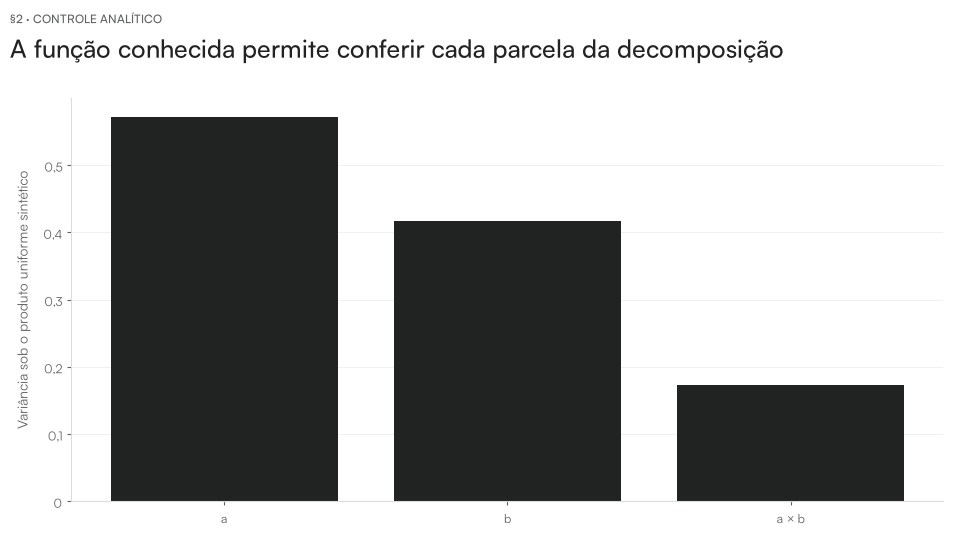

In [4]:
# Referência controlada: grade cartesiana balanceada, sem relação com pacientes.
u = np.linspace(-1, 1, 9)
sintetico = pd.DataFrame(itertools.product(u, u), columns=["a", "b"])


def aditiva(d):
    return 2 + np.exp(d["a"].to_numpy()) - d["b"].to_numpy()


def multiplicativa(d):
    return d["a"].to_numpy() * d["b"].to_numpy()


print("Pontos sintéticos:", SP.pt_int(len(sintetico)))

s = (aditiva(sintetico) + multiplicativa(sintetico)).reshape(len(u), len(u))
d = G.decompor_superficie(s, np.ones(len(u)), np.ones(len(u)))
assert np.max(np.abs(s - d["reconstrucao"])) < 1e-12
assert np.allclose(d["fjk"] @ d["pesos_k"], 0, atol=1e-12)
assert np.allclose(d["pesos_j"] @ d["fjk"], 0, atol=1e-12)
assert np.isclose(d["variancias"].sum(), d["total"])
assert np.allclose(d["fjk"], np.outer(u, u), atol=1e-12)
print(
    "Erro máximo de reconstrução sintética:",
    SP.pt_sig(np.max(np.abs(s - d["reconstrucao"])), 4),
)
print(
    "Erro interação vs produto conhecido:",
    SP.pt_sig(np.max(np.abs(d["fjk"] - np.outer(u, u))), 4),
)
print(
    "Média condicional máxima da interação:",
    SP.pt_sig(np.max(np.abs(d["fjk"] @ d["pesos_k"])), 4),
)
print(
    "Variância total e soma das parcelas:",
    SP.pt(d["total"], 8),
    SP.pt(d["variancias"].sum(), 8),
)
fig, ax = plt.subplots(figsize=SP.SLOT)
ax.bar(["a", "b", "a × b"], d["variancias"], color=SP.ESCURO)
ax.set(ylabel="Variância sob o produto uniforme sintético")
SP.titulo(
    fig,
    "A função conhecida permite conferir cada parcela da decomposição",
    "§2 · Controle analítico",
)
SP.salvar(fig, "decomposition-controle")
plt.show()

**O que olhar.**

- A interação recupera o produto conhecido porque a referência é independente e simétrica.
- O intercepto não é a previsão na origem: é a média sob a referência declarada.

## §3 — Conferência independente na superfície SRAG

Reconstruímos as médias ponderadas com laços escalares, sem chamar o núcleo para definir seus componentes. A verificação alcança a superfície inteira.

In [5]:
# Grade e pesos definidos antes de inspecionar a superfície.
faixas = pd.qcut(painel["idade_anos"], q=8, duplicates="drop")
resumo_idade = painel.groupby(faixas, observed=True)["idade_anos"].agg(
    ["median", "size"]
)
idades = resumo_idade["median"].to_numpy()
wj = resumo_idade["size"].to_numpy(dtype=float)
estados = list(xf["saturacao"].cat.categories)
wk = (
    painel["saturacao"]
    .value_counts()
    .reindex(estados, fill_value=0)
    .to_numpy(dtype=float)
)
pontos = pd.DataFrame(
    itertools.product(idades, estados), columns=["idade_anos", "saturacao"]
)
superficie = G.pd_empirica(prever, xf, pontos).reshape(len(idades), len(estados))
dec = G.decompor_superficie(superficie, wj, wk)
recon_error = np.max(np.abs(superficie - dec["reconstrucao"]))
assert recon_error < 1e-12
assert np.isclose(dec["variancias"].sum(), dec["total"], atol=1e-14)
print(
    "Idades representativas:",
    SP.pt_int(len(idades)),
    "| estados:",
    SP.pt_int(len(estados)),
)
print("Intercepto da superfície:", SP.pt(dec["f0"], 6))
print("Erro máximo de reconstrução:", SP.pt_sig(recon_error, 4))
print("Soma das variâncias:", SP.pt(dec["variancias"].sum(), 10))
print("Variância da superfície sob o produto:", SP.pt(dec["total"], 10))
partes = pd.DataFrame(
    {
        "componente": ["idade", "saturação", "interação"],
        "variância": dec["variancias"],
        "fração no produto": dec["variancias"] / dec["total"],
    }
)
print(SP.tabela(partes, casas=6))
print("Pesos da idade:", ", ".join(SP.pt(v, 4) for v in dec["pesos_j"]))
print("Pesos da saturação:", ", ".join(SP.pt(v, 4) for v in dec["pesos_k"]))

w1, w2 = wj / wj.sum(), wk / wk.sum()
base = sum(
    w1[i] * w2[j] * superficie[i, j] for i in range(len(w1)) for j in range(len(w2))
)
main1 = np.array(
    [
        sum(w2[j] * superficie[i, j] for j in range(len(w2))) - base
        for i in range(len(w1))
    ]
)
main2 = np.array(
    [
        sum(w1[i] * superficie[i, j] for i in range(len(w1))) - base
        for j in range(len(w2))
    ]
)
rest = superficie - base - main1[:, None] - main2[None, :]
assert np.allclose(rest, dec["fjk"], atol=1e-12)
assert np.allclose(rest @ w2, 0, atol=1e-12)
assert np.allclose(w1 @ rest, 0, atol=1e-12)
print(
    "Erro da interação por laços independentes:",
    SP.pt_sig(np.max(np.abs(rest - dec["fjk"])), 4),
)
print("Maior média condicional de linha:", SP.pt_sig(np.max(np.abs(rest @ w2)), 4))
print("Maior média condicional de coluna:", SP.pt_sig(np.max(np.abs(w1 @ rest)), 4))
# Uma transferência arbitrária mantém a soma e quebra a restrição de centralização.
deslocamento = np.linspace(-0.01, 0.01, len(w1))
shift_main = main1 + deslocamento
shift_rest = rest - deslocamento[:, None]
assert np.allclose(superficie, base + shift_main[:, None] + main2[None, :] + shift_rest)
print(
    "Erro após redistribuição arbitrária:",
    SP.pt_sig(
        np.max(
            np.abs(
                superficie - (base + shift_main[:, None] + main2[None, :] + shift_rest)
            )
        ),
        4,
    ),
)
print(
    "Média condicional máxima após redistribuição:",
    SP.pt(np.max(np.abs(shift_rest @ w2)), 6),
)
print("Apenas somar corretamente não identifica os componentes.")

Idades representativas: 8 | estados: 3
Intercepto da superfície: 0,220314
Erro máximo de reconstrução: 0,0000
Soma das variâncias: 0,0122997211
Variância da superfície sob o produto: 0,0122997211
componente variância fração no produto
     idade  0,010524          0,855655
 saturação  0,001587          0,129004
 interação  0,000189          0,015341
Pesos da idade: 0,1250, 0,1250, 0,1250, 0,1250, 0,1250, 0,1250, 0,1250, 0,1250
Pesos da saturação: 0,1348, 0,2246, 0,6406
Erro da interação por laços independentes: 0,0000
Maior média condicional de linha: 0,0000
Maior média condicional de coluna: 0,0000
Erro após redistribuição arbitrária: 2,7756×10⁻¹⁷
Média condicional máxima após redistribuição: 0,010000
Apenas somar corretamente não identifica os componentes.


**O que olhar.**

- A verificação independente confere mais que a identidade da soma: confere as restrições que identificam os termos.
- Redistribuir uma função entre componentes preserva a soma e destrói a interpretação adotada.

### O que o livro diz

O [capítulo de Molnar](https://christophm.github.io/interpretable-ml-book/decomposition.html)
mostra que uma soma de componentes precisa de restrições para ter uma
interpretação definida. O exemplo inicial usa ALE; neste caderno, a mesma
função sintética é conferida sob uma decomposição produto explicitamente escolhida.

Os laços na superfície SRAG verificam médias ponderadas, componentes e
ortogonalidade nessa referência. Isso alcança a tabela discretizada, sem
implementar uma ANOVA funcional geral do XGBoost ou sua extensão para a
distribuição dependente. A reconstrução não certifica plausibilidade clínica
das combinações usadas para construir a superfície.

## §4 — Escopo frente ao capítulo e fórmula analítica

O exemplo inicial do capítulo usa ALE para decompor uma função conhecida. O capítulo também desenvolve ANOVA funcional sob medida produto e sua extensão para dependência. Nosso estudo escolhe a ANOVA produto de uma PD conjunta discretizada, sem implementar a extensão generalizada, a decomposição ALE do exemplo ou a decomposição completa do XGBoost.

Para a mesma função sintética do livro, sob a grade produto simétrica e uniforme, o intercepto é a média de `2 + exp(a)`, os principais são `exp(a) − média(exp(a))` e `−b`, e a interação é `a × b`. Conferimos esses componentes analíticos além da soma. Isso valida o estimador escolhido, não a equivalência com a figura ALE do livro.


In [6]:
conhecida = 2 + np.exp(u[:, None]) - u[None, :] + np.outer(u, u)
analitica = G.decompor_superficie(conhecida, np.ones(len(u)), np.ones(len(u)))
expected0 = 2 + np.exp(u).mean()
expectedj, expectedk = np.exp(u) - np.exp(u).mean(), -u
err_componentes = max(
    abs(analitica["f0"] - expected0),
    np.max(np.abs(analitica["fj"] - expectedj)),
    np.max(np.abs(analitica["fk"] - expectedk)),
    np.max(np.abs(analitica["fjk"] - np.outer(u, u))),
)
assert err_componentes < 1e-12
print(
    "Erro máximo dos componentes vs fórmula analítica:", SP.pt_sig(err_componentes, 4)
)
print("Objeto SRAG decomposto: PD de idade × saturação, não o preditor completo.")
print("Referência: produto das marginais discretizadas, não a conjunta observada.")

Erro máximo dos componentes vs fórmula analítica: 8,8818×10⁻¹⁶
Objeto SRAG decomposto: PD de idade × saturação, não o preditor completo.
Referência: produto das marginais discretizadas, não a conjunta observada.


## Fechamento — a soma sozinha não identifica os componentes

- A função sintética permite conferir componentes conhecidos; os laços
  independentes verificam as médias e restrições na superfície SRAG.
- Reconstrução e ortogonalidade dependem dos pesos produto escolhidos.
  Redistribuir valores arbitrariamente entre componentes pode conservar a
  soma e perder a interpretação.
- A conferência vale para a superfície finita. Não replica a figura ALE do
  livro, não decompõe todas as entradas do preditor e não transfere a identidade
  de variâncias à distribuição conjunta observada.

In [7]:
pd.testing.assert_frame_equal(xf, original_xf)
assert bytes(model.get_booster().save_raw()) == model_bytes
print("Matriz de fundo e preditor permaneceram intactos:", True)

Matriz de fundo e preditor permaneceram intactos: True


## Referências

Molnar — [cap. 22](https://christophm.github.io/interpretable-ml-book/decomposition.html). Referências completas e configuração no [README](../README.md).